# 2 · Binomial trees, Monte Carlo and exotic options
* Convergence of the Cox-Ross-Rubinstein tree to Black-Scholes
* Early-exercise premium of American puts (tree vs Longstaff-Schwartz Monte Carlo)
* Asian and barrier options with Monte Carlo confidence intervals

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from derivpricer import black_scholes as bs, trees, monte_carlo as mc

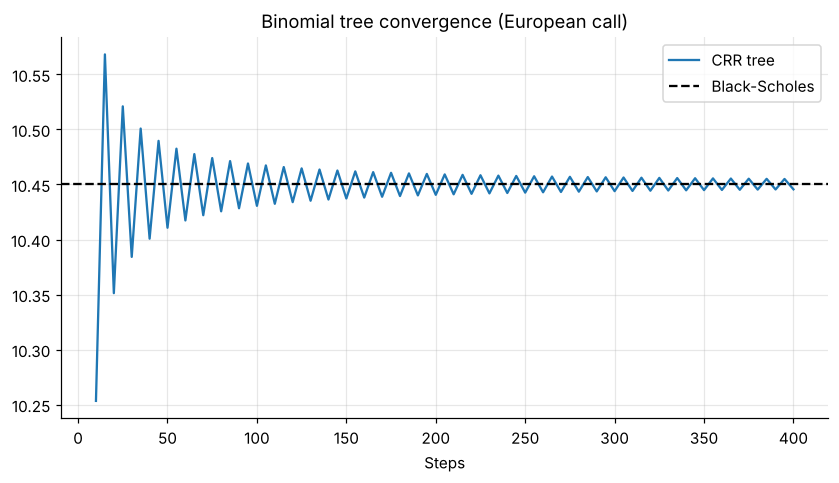

In [2]:
S0, K, T, r, sigma = 100, 100, 1.0, 0.05, 0.20
steps = np.arange(10, 401, 5)
crr = [trees.crr_price(S0, K, T, r, sigma, n) for n in steps]
plt.plot(steps, crr, label="CRR tree"); plt.axhline(bs.price(S0, K, T, r, sigma), color="k", ls="--", label="Black-Scholes")
plt.title("Binomial tree convergence (European call)"); plt.xlabel("Steps"); plt.legend()
plt.savefig(IMG / "crr_convergence.png", bbox_inches="tight"); plt.show()

## American vs European puts

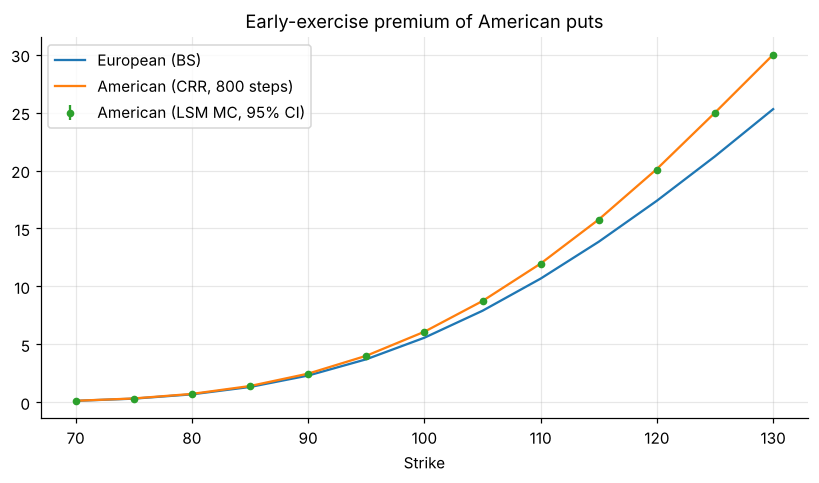

,strike,european,american_tree,american_lsm,lsm_se,premium
0,70,0.1262,0.1310,0.1291,0.0038,0.0049
1,75,0.3166,0.3312,0.3239,0.0062,0.0146
2,80,0.6872,0.7237,0.7135,0.0097,0.0365
3,85,1.3238,1.4055,1.3887,0.0141,0.0817
4,90,2.3101,2.4737,2.4700,0.0192,0.1636
5,95,3.7133,4.0147,4.0108,0.0244,0.3015
6,100,5.5735,6.0894,6.1001,0.0292,0.5159
7,105,7.9004,8.7418,8.7591,0.0332,0.8414
8,110,10.6753,11.9734,11.9604,0.0347,1.2981
9,115,13.8580,15.7784,15.7485,0.0339,1.9204


In [3]:
strikes = np.arange(70, 131, 5)
rows = []
for k in strikes:
    eu = bs.price(S0, k, T, r, sigma, "put")
    am_tree = trees.crr_price(S0, k, T, r, sigma, 800, "put", american=True)
    am_lsm = mc.american_lsm(S0, k, T, r, sigma, "put", n_paths=60_000)
    rows.append((k, eu, am_tree, am_lsm.price, am_lsm.std_error))
amer = pd.DataFrame(rows, columns=["strike", "european", "american_tree", "american_lsm", "lsm_se"])
amer["premium"] = amer.american_tree - amer.european
plt.plot(amer.strike, amer.european, label="European (BS)")
plt.plot(amer.strike, amer.american_tree, label="American (CRR, 800 steps)")
plt.errorbar(amer.strike, amer.american_lsm, yerr=1.96 * amer.lsm_se, fmt="o", ms=4, label="American (LSM MC, 95% CI)")
plt.title("Early-exercise premium of American puts"); plt.xlabel("Strike"); plt.legend()
plt.savefig(IMG / "american_vs_european.png", bbox_inches="tight"); plt.show()
amer.round(4)

## Exotics: Asian and barrier options

In [4]:
vanilla = mc.european(S0, K, T, r, sigma)
asian = mc.asian_arithmetic(S0, K, T, r, sigma)
uai = mc.barrier(S0, K, 120, T, r, sigma, kind="up-and-in")
uao = mc.barrier(S0, K, 120, T, r, sigma, kind="up-and-out")
dai = mc.barrier(S0, K, 80, T, r, sigma, option="put", kind="down-and-in")
summary = pd.DataFrame({
    "contract": ["European call", "Asian (arith.) call", "Up-and-in call H=120", "Up-and-out call H=120", "Down-and-in put H=80"],
    "price": [x.price for x in (vanilla, asian, uai, uao, dai)],
    "std_error": [x.std_error for x in (vanilla, asian, uai, uao, dai)]})
print(f"In-out parity check: UAI + UAO = {uai.price + uao.price:.4f} vs vanilla {mc.barrier(S0, K, 0, T, r, sigma).price:.4f}")
summary.round(4)

In-out parity check: UAI + UAO = 10.4675 vs vanilla 10.4675


,contract,price,std_error
0,European call,10.4763,0.0331
1,Asian (arith.) call,5.8101,0.0255
2,Up-and-in call H=120,9.1568,0.0480
3,Up-and-out call H=120,1.3107,0.0107
4,Down-and-in put H=80,3.8322,0.0271


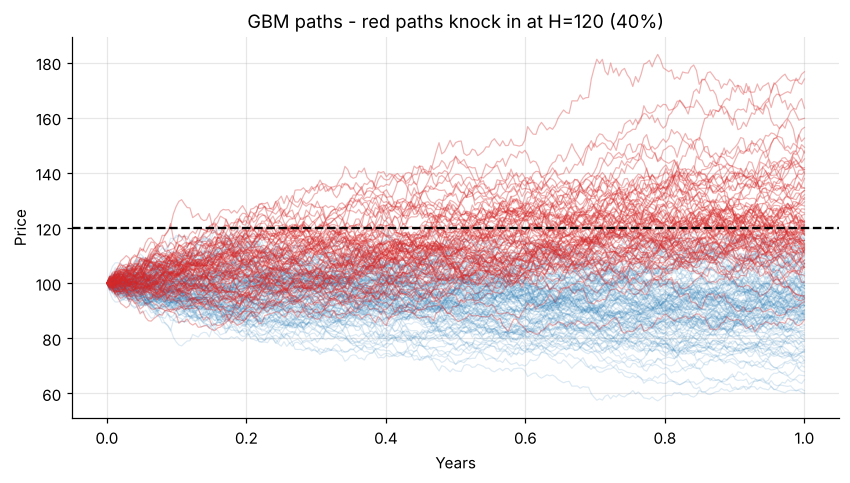

In [5]:
paths = mc.gbm_paths(S0, r, sigma, T, 252, 200, seed=7)
hit = paths.max(axis=0) >= 120
t = np.linspace(0, T, 253)
plt.plot(t, paths[:, ~hit], color="tab:blue", alpha=0.15, lw=0.8)
plt.plot(t, paths[:, hit], color="tab:red", alpha=0.35, lw=0.8)
plt.axhline(120, color="k", ls="--"); plt.title(f"GBM paths - red paths knock in at H=120 ({hit.mean():.0%})")
plt.xlabel("Years"); plt.ylabel("Price"); plt.show()